# 10 — Pipeline Completo: Car Parts Dataset

**Dissertação**: Análise Comparativa de Algoritmos de Regressão para Previsão em Séries Temporais  
**Autora**: Luana Gomes de Souza  
**Etapa**: Validade Externa — segundo dataset para reforçar comparação

---
### Objetivo
Replicar o pipeline experimental dos notebooks 02–07 no **Car Parts Dataset** (Monash Archive)  
como segundo conjunto de dados, permitindo avaliar a validade externa dos resultados M4.

### Características do Car Parts Dataset
- **Fonte**: Hyndman (2015), pacote R `expsmooth` — Monash Time Series Archive
- **Séries**: 2.674 séries mensais de demanda de peças automotivas
- **Período**: Janeiro 1998 a Março 2002 (51 observações)
- **Natureza**: Demanda intermitente — alta proporção de zeros (zeros = sem demanda no mês)
- **Desafio**: MAPE é indefinido quando o valor real é zero → usar MAE como métrica complementar

### Protocolo experimental (idêntico ao M4)
| Parâmetro | Valor |
|---|---|
| SEED | 42 |
| H (horizonte) | 18 |
| MIN_TRAIN | 24 |
| N_ORIGINS | 3 |
| SEASON | 12 |

### Modelos avaliados (9 no total)
Persistência, Média histórica, Sazonal ingênuo, Holt-Winters, SES,  
SARIMA heurístico, Random Forest, Gradient Boosting, SVR  
**SARIMA automático**: excluído — restrição operacional (custo computacional, mesmo critério do notebook 08)

### Nota sobre zeros
O Car Parts é um dataset de **demanda intermitente** — a maioria das séries tem >50% de zeros.  
O MAPE é indefinido quando `y_true == 0`. A função `calc_mape` já usa máscara sobre não-zeros  
e retorna `NaN` quando todos os valores do período de teste são zero.  
Nesses casos, **o MAE é a métrica principal de comparação** (sempre definido).

## 1. Imports, configurações e caminhos

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time
import json
import shutil
from pathlib import Path
from datetime import datetime
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from statsmodels.tsa.holtwinters import ExponentialSmoothing, SimpleExpSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings('ignore')
np.random.seed(42)

# ── Resolução de caminhos (funciona com cwd em autopred/ ou notebooks/) ───────
_root = Path.cwd().resolve()
for _candidate in (_root, *_root.parents):
    if (_candidate / 'notebooks').is_dir() and (_candidate / 'results').is_dir():
        PROJECT_ROOT = _candidate
        break
else:
    PROJECT_ROOT = _root

# ── Diretório de dados do Car Parts ───────────────────────────────────────────
CP_DATA_DIR = PROJECT_ROOT / 'data' / 'raw' / 'car_parts'
CP_DATA_DIR.mkdir(parents=True, exist_ok=True)

_tsf_candidates = [
    CP_DATA_DIR / 'car_parts_dataset_without_missing_values.tsf',
    PROJECT_ROOT / 'data' / 'raw' / 'car_parts_dataset_without_missing_values.tsf',
]
_tsf_source = next((p for p in _tsf_candidates if p.exists()), None)
if _tsf_source is None:
    raise FileNotFoundError(
        'car_parts_dataset_without_missing_values.tsf não encontrado.\n'
        'Verificado em:\n' + '\n'.join(f'  {p}' for p in _tsf_candidates)
    )

CP_TSF_PATH = CP_DATA_DIR / 'car_parts_dataset_without_missing_values.tsf'
if not CP_TSF_PATH.exists():
    shutil.copy(_tsf_source, CP_TSF_PATH)
    print(f'Arquivo copiado para: {CP_TSF_PATH}')

RESULT_DIR = PROJECT_ROOT / 'results' / 'car_parts'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ── Parâmetros do protocolo (idênticos aos notebooks 02–07) ───────────────────
SEED      = 42
H         = 18
MIN_TRAIN = 24
N_ORIGINS = 3
SEASON    = 12

# ── Hiperparâmetros ML (idênticos aos notebooks 05–07) ────────────────────────
N_LAGS           = 12
N_ESTIMATORS     = 100
MIN_SAMPLES_LEAF = 2

# Random Forest: n_estimators reduzido só para este dataset (2674 séries)
# para evitar lentidão/travamento. Os demais modelos usam N_ESTIMATORS.
CP_N_ESTIMATORS  = 30
LEARNING_RATE    = 0.1
GBT_MAX_DEPTH    = 3
GBT_SUBSAMPLE    = 0.8
SVR_C            = 1.0
SVR_EPS          = 0.1
SVR_KERNEL       = 'rbf'
SVR_GAMMA        = 'scale'

# ── SARIMA heurístico (mesma ordem do notebook 04) ────────────────────────────
SARIMA_ORDER          = (1, 1, 1)
SARIMA_SEASONAL_ORDER = (1, 1, 0, 12)
SARIMA_TIME_LIMIT     = 60.0

# ── Cache: True força re-execução mesmo com arquivos já salvos ───────────────
FORCE_RERUN = False

# ── Limite opcional de séries a processar (debug/velocidade) ─────────────────
# Processa no máximo N_SERIES_LIMIT séries. Use None para rodar TODAS (2674).
N_SERIES_LIMIT = None

print(f'PROJECT_ROOT = {PROJECT_ROOT}')
print(f'CP_TSF_PATH  = {CP_TSF_PATH}')
print(f'RESULT_DIR   = {RESULT_DIR}')
print(f'FORCE_RERUN  = {FORCE_RERUN}')
print('Configuração carregada OK')

PROJECT_ROOT = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred
CP_TSF_PATH  = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\data\raw\car_parts\car_parts_dataset_without_missing_values.tsf
RESULT_DIR   = C:\Users\Usuario\Desktop\Mestrado\Mestrado - aula\dissertação\autopred\results\car_parts
FORCE_RERUN  = False
Configuração carregada OK


## 2. Carregador do formato TSF (Monash Archive)

In [2]:
def load_car_parts_tsf(tsf_path):
    """
    Carrega o Car Parts dataset do formato TSF (Monash Archive) sem dependências externas.

    Formato TSF do arquivo:
      - Linhas de comentário: começam com '#'
      - Metadados: começam com '@' (ex: @relation, @attribute, @frequency)
      - Início dos dados: linha '@data'
      - Cada linha de dado: nome:timestamp:val1,val2,...

    Retorna DataFrame com colunas [unique_id, step, y] ordenado por série e passo.
    """
    records  = []
    in_data  = False

    with open(tsf_path, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            if line.lower() == '@data':
                in_data = True
                continue
            if line.startswith('@'):
                continue
            if not in_data:
                continue

            # Linha de dado: T1:1998-01-01 00-00-00:0,0,0,...
            parts = line.split(':')
            if len(parts) < 3:
                continue

            series_name = parts[0].strip()
            values_str  = parts[-1].strip()   # último campo = valores CSV

            try:
                values = [float(v) for v in values_str.split(',') if v.strip()]
            except ValueError:
                continue

            for step, val in enumerate(values, start=1):
                records.append({
                    'unique_id': series_name,
                    'step'     : step,
                    'y'        : val,
                })

    df = pd.DataFrame(records, columns=['unique_id', 'step', 'y'])
    return df.sort_values(['unique_id', 'step']).reset_index(drop=True)


print('Carregando Car Parts dataset...')
t0 = time.time()
df_raw = load_car_parts_tsf(CP_TSF_PATH)
print(f'Carregado em {time.time() - t0:.2f}s')
print(f'\nShape     : {df_raw.shape}')
print(f'Séries    : {df_raw["unique_id"].nunique():,}')
print(f'Obs/série : {df_raw.groupby("unique_id")["y"].count().unique()} (equallength)')
print(f'\nPrimeiras linhas:')
print(df_raw.head(8).to_string(index=False))

Carregando Car Parts dataset...
Carregado em 0.09s

Shape     : (136374, 3)
Séries    : 2,674
Obs/série : [51] (equallength)

Primeiras linhas:
unique_id  step   y
       T1     1 0.0
       T1     2 0.0
       T1     3 0.0
       T1     4 0.0
       T1     5 0.0
       T1     6 0.0
       T1     7 2.0
       T1     8 0.0


## 3. Análise exploratória (EDA)

=== Comprimento das séries ===
count    2674.0
mean       51.0
std         0.0
min        51.0
25%        51.0
50%        51.0
75%        51.0
max        51.0

=== Proporção de zeros por série ===
count    2674.0000
mean        0.7591
std         0.1734
min         0.2549
25%         0.6471
50%         0.8039
75%         0.9020
max         0.9804

Séries com >80% zeros : 1383 (51.7%)
Séries com >50% zeros : 2383 (89.1%)
Séries com todos zeros: 0

=== Estatísticas dos valores não-zero ===
count    32854.000
mean         2.015
std          1.865
min          1.000
25%          1.000
50%          1.000
75%          2.000
max         52.000


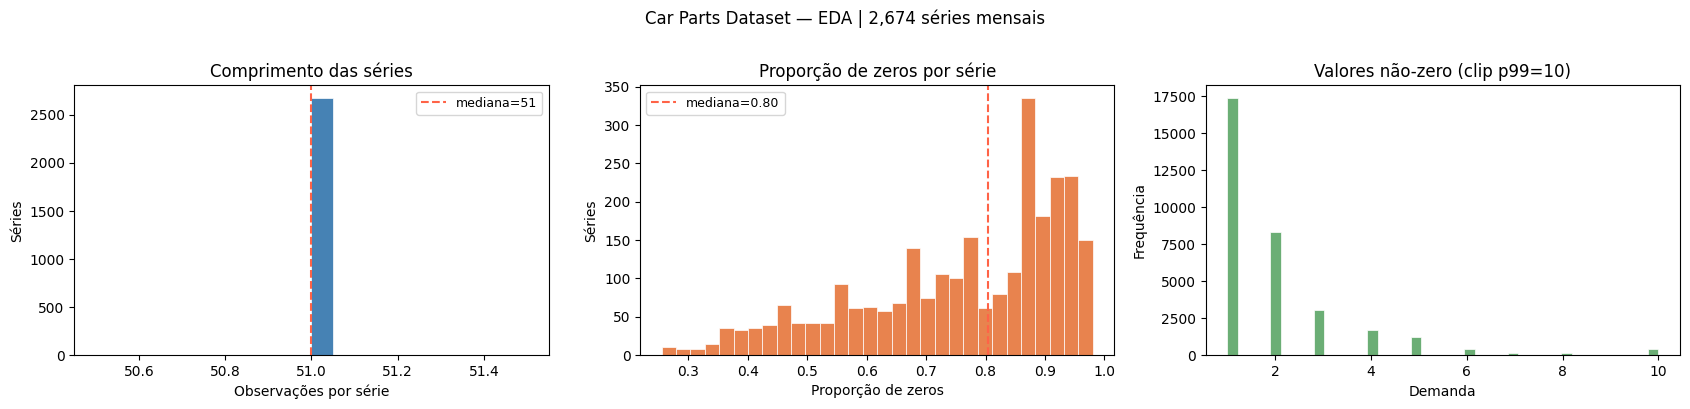

Figura salva: fig_eda_car_parts.png


In [3]:
# Comprimento e zeros por série
series_lengths = df_raw.groupby('unique_id')['y'].count().rename('length')
zero_prop      = df_raw.groupby('unique_id')['y'].apply(
    lambda s: (s == 0).mean()
).rename('zero_prop')

print('=== Comprimento das séries ===')
print(series_lengths.describe().to_string())

print('\n=== Proporção de zeros por série ===')
print(zero_prop.describe().round(4).to_string())

print(f'\nSéries com >80% zeros : {(zero_prop > 0.80).sum()} ({(zero_prop > 0.80).mean()*100:.1f}%)')
print(f'Séries com >50% zeros : {(zero_prop > 0.50).sum()} ({(zero_prop > 0.50).mean()*100:.1f}%)')
print(f'Séries com todos zeros: {(zero_prop == 1.0).sum()}')

# Estatísticas dos valores não-zero
nonzero = df_raw[df_raw['y'] > 0]['y']
print(f'\n=== Estatísticas dos valores não-zero ===')
print(nonzero.describe().round(3).to_string())

# Gráficos EDA
fig, axes = plt.subplots(1, 3, figsize=(17, 4))

# Comprimento das séries
axes[0].hist(series_lengths, bins=20, color='steelblue', edgecolor='white', linewidth=0.5)
axes[0].axvline(series_lengths.median(), color='tomato', linestyle='--', linewidth=1.5,
                label=f'mediana={series_lengths.median():.0f}')
axes[0].set_title('Comprimento das séries')
axes[0].set_xlabel('Observações por série')
axes[0].set_ylabel('Séries')
axes[0].legend(fontsize=9)

# Proporção de zeros
axes[1].hist(zero_prop, bins=30, color='#E8834E', edgecolor='white', linewidth=0.5)
axes[1].axvline(zero_prop.median(), color='tomato', linestyle='--', linewidth=1.5,
                label=f'mediana={zero_prop.median():.2f}')
axes[1].set_title('Proporção de zeros por série')
axes[1].set_xlabel('Proporção de zeros')
axes[1].set_ylabel('Séries')
axes[1].legend(fontsize=9)

# Distribuição dos valores não-zero
clip_val = nonzero.quantile(0.99)
axes[2].hist(nonzero.clip(upper=clip_val), bins=40, color='#6BAE75',
             edgecolor='white', linewidth=0.5)
axes[2].set_title(f'Valores não-zero (clip p99={clip_val:.0f})')
axes[2].set_xlabel('Demanda')
axes[2].set_ylabel('Frequência')

plt.suptitle(
    f'Car Parts Dataset — EDA | {df_raw["unique_id"].nunique():,} séries mensais',
    fontsize=12, y=1.01
)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_eda_car_parts.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva: fig_eda_car_parts.png')

## 4. Seleção de séries válidas

Critério: comprimento ≥ `MIN_TRAIN + H = 42`.  
O Car Parts tem `@equallength true` (51 obs cada) — todas as séries passam no filtro.

In [4]:
min_len    = MIN_TRAIN + H   # = 42
valid_mask = series_lengths >= min_len
valid_ids  = series_lengths[valid_mask].index.tolist()

print(f'Comprimento mínimo requerido: MIN_TRAIN + H = {MIN_TRAIN} + {H} = {min_len}')
print(f'Séries totais    : {len(series_lengths):,}')
print(f'Séries válidas   : {len(valid_ids):,}')
print(f'Séries excluídas : {(~valid_mask).sum()}')

train_df = df_raw[df_raw['unique_id'].isin(valid_ids)].copy()
print(f'\nDataFrame de trabalho: {len(train_df):,} linhas | {train_df["unique_id"].nunique():,} séries')

# Zero proportion nas séries válidas
zero_prop_valid = zero_prop[valid_ids]
print(f'\n=== Zeros nas séries válidas ===')
print(f'Proporção mediana  : {zero_prop_valid.median():.2%}')
print(f'Séries >50% zeros  : {(zero_prop_valid > 0.5).sum()} ({(zero_prop_valid > 0.5).mean()*100:.1f}%)')

# Verificação das janelas rolling para uma série de 51 obs
origins_ex = np.linspace(MIN_TRAIN, 51 - H, N_ORIGINS, dtype=int).tolist()
origins_ex = sorted(set(origins_ex))
print(f'\nOrigens rolling (série de 51 obs, H={H}, N_ORIGINS={N_ORIGINS}): {origins_ex}')
print(f'Janelas por série: {len(origins_ex)}')
print(f'Total esperado de janelas OK: {len(valid_ids) * len(origins_ex):,}')

Comprimento mínimo requerido: MIN_TRAIN + H = 24 + 18 = 42
Séries totais    : 2,674
Séries válidas   : 2,674
Séries excluídas : 0

DataFrame de trabalho: 136,374 linhas | 2,674 séries

=== Zeros nas séries válidas ===
Proporção mediana  : 80.39%
Séries >50% zeros  : 2383 (89.1%)

Origens rolling (série de 51 obs, H=18, N_ORIGINS=3): [24, 28, 33]
Janelas por série: 3
Total esperado de janelas OK: 8,022


## 5. Funções base do pipeline

Replicadas diretamente dos notebooks 02–07. Mesmos nomes e assinaturas para consistência.

In [5]:
def make_rolling_windows(series, horizon, min_train, n_origins):
    n = len(series)
    if n < min_train + horizon:
        return []
    last_origin  = n - horizon
    first_origin = min_train
    if last_origin <= first_origin:
        return []
    origins = np.linspace(first_origin, last_origin, n_origins, dtype=int).tolist()
    origins = sorted(set(origins))
    return [
        {'origin': o, 'train': series[:o], 'test': series[o:o+horizon]}
        for o in origins if len(series[o:o+horizon]) == horizon
    ]


def calc_mape(y_true, y_pred):
    """
    MAPE calculado apenas sobre valores não-zero.
    Retorna NaN se todos os valores reais forem zero (demanda nula no período de teste).
    Nesses casos, o MAE é a métrica principal de comparação.
    """
    mask = y_true != 0
    if mask.sum() == 0:
        return np.nan
    return float(np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100)


def calc_metrics(y_true, y_pred):
    return {
        'mape': calc_mape(y_true, y_pred),
        'mae' : float(mean_absolute_error(y_true, y_pred)),
        'r2'  : float(r2_score(y_true, y_pred))
    }


def run_pipeline(train_df, horizon, min_train, n_origins, model_name, predict_fn,
                 print_every=100, limit=None):
    records = []
    ids     = train_df['unique_id'].unique()
    if limit is not None:
        ids = ids[:limit]
    total   = len(ids)

    for i, uid in enumerate(ids):
        if i == 0 or (i + 1) % print_every == 0 or (i + 1) == total:
            print(f'  [{i+1}/{total}] {uid}')

        values  = train_df[train_df['unique_id'] == uid]['y'].values.astype(float)
        windows = make_rolling_windows(values, horizon, min_train, n_origins)

        if not windows:
            records.append({
                'unique_id': uid, 'model': model_name,
                'origin': None, 'n_train': None,
                'mape': None, 'mae': None, 'r2': None,
                'exec_time_s': None, 'status': 'SKIP_SHORT'
            })
            continue

        for win in windows:
            t0 = time.perf_counter()
            try:
                pred    = predict_fn(win['train'], horizon)
                metrics = calc_metrics(win['test'], pred)
                status  = 'OK'
            except Exception as e:
                metrics = {'mape': None, 'mae': None, 'r2': None}
                status  = f'ERROR: {str(e)[:80]}'

            records.append({
                'unique_id'  : uid,
                'model'      : model_name,
                'origin'     : win['origin'],
                'n_train'    : len(win['train']),
                **metrics,
                'exec_time_s': time.perf_counter() - t0,
                'status'     : status
            })

    return pd.DataFrame(records)


print('Funções base OK')

Funções base OK


## 6. Modelos estatísticos e baselines

Implementações idênticas aos notebooks 02–04.

In [16]:
# ── Baselines ingênuos ────────────────────────────────────────────────────────
def baseline_persistence(train, horizon):
    return np.full(horizon, train[-1])

def baseline_mean(train, horizon):
    return np.full(horizon, np.mean(train))

def baseline_seasonal_naive(train, horizon, season=SEASON):
    n = len(train)
    if n < season:
        return np.full(horizon, train[-1])
    preds = []
    for h in range(1, horizon + 1):
        idx = n - season + ((h - 1) % season)
        idx = min(idx, n - 1)
        preds.append(train[idx])
    return np.array(preds)


# ── Holt-Winters (notebook 02) ────────────────────────────────────────────────
def holt_winters(train, horizon, season=SEASON):
    n = len(train)
    if n < 2 * season:
        return baseline_seasonal_naive(train, horizon, season)

    best_model = None
    best_aic   = np.inf

    seasonal_types = ['add']
    if np.all(train > 0):
        seasonal_types.append('mul')

    for stype in seasonal_types:
        try:
            model = ExponentialSmoothing(
                train,
                trend='add',
                seasonal=stype,
                seasonal_periods=season,
                initialization_method='estimated'
            ).fit(optimized=True)
            if model.aic < best_aic:
                best_aic   = model.aic
                best_model = model
        except Exception:
            continue

    if best_model is None:
        return baseline_seasonal_naive(train, horizon, season)

    return best_model.forecast(horizon)


# ── SES (notebook 03) ─────────────────────────────────────────────────────────
def model_ses(train, horizon):
    try:
        fit = SimpleExpSmoothing(
            train, initialization_method='estimated'
        ).fit(optimized=True)
        return fit.forecast(horizon)
    except Exception:
        return np.full(horizon, np.mean(train))


# ── SARIMA heurístico (notebook 04) ───────────────────────────────────────────
# SARIMA automático EXCLUÍDO: custo computacional excessivo (2674 séries × 3 origens).
# Mesma restrição operacional documentada no notebook 08 para o M4.
def sarima_heuristic(train, horizon,
                     order=SARIMA_ORDER,
                     seasonal_order=SARIMA_SEASONAL_ORDER,
                     time_limit=SARIMA_TIME_LIMIT):
    """
    SARIMA(1,1,1)(1,1,0)[12] com ordem fixa heurística.
    Séries constantes (ex: todos zeros) causam erro de convergência —
    fallback para sazonal ingênuo nesses casos.
    """
    if np.std(train) == 0:
        return baseline_seasonal_naive(train, horizon)

    t0 = time.perf_counter()
    try:
        model = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        fit = model.fit(disp=False, maxiter=50)

        if time.perf_counter() - t0 > time_limit:
            return baseline_seasonal_naive(train, horizon)

        return np.array(fit.forecast(steps=horizon))
    except Exception:
        return baseline_seasonal_naive(train, horizon)


# Verificação com série de zeros (caso extremo do Car Parts)
ex_zeros = np.zeros(30, dtype=float)
print('Verificação com série de zeros (30 obs):')
print(f'  Persistência   : {baseline_persistence(ex_zeros, 3)}  | correto={np.all(baseline_persistence(ex_zeros, 3) == 0)}')
print(f'  Sazonal ing.   : {baseline_seasonal_naive(ex_zeros, 3)}  | correto={np.all(baseline_seasonal_naive(ex_zeros, 3) == 0)}')
print(f'  Holt-Winters   : {holt_winters(ex_zeros, 3).round(3)} | zeros={np.all(holt_winters(ex_zeros, 3) == 0)}')
print(f'  SES            : {model_ses(ex_zeros, 3).round(3)} | zeros={np.all(model_ses(ex_zeros, 3) == 0)}')
print(f'  SARIMA (caiu no fallback): {sarima_heuristic(ex_zeros, 3)}')
print('\nModelos estatísticos OK')

Verificação com série de zeros (30 obs):
  Persistência   : [0. 0. 0.]  | correto=True
  Sazonal ing.   : [0. 0. 0.]  | correto=True
  Holt-Winters   : [0. 0. 0.] | zeros=True
  SES            : [0. 0. 0.] | zeros=True
  SARIMA (caiu no fallback): [0. 0. 0.]

Modelos estatísticos OK


## 7. Modelos ML — engenharia de features e predição recursiva

Implementações idênticas aos notebooks 05–07.

In [6]:
def build_features(series, n_lags=N_LAGS, season=SEASON):
    """
    Idêntica aos notebooks 05, 06 e 07.
    Features: lag_1..lag_L, roll_mean, roll_std, lag_season, lag_season2 (se disponível).
    """
    n        = len(series)
    lag_cols = {f'lag_{i}': np.full(n, np.nan) for i in range(1, n_lags + 1)}
    for i in range(1, n_lags + 1):
        lag_cols[f'lag_{i}'][i:] = series[:-i]

    df = pd.DataFrame(lag_cols)
    df['roll_mean'] = df[[f'lag_{i}' for i in range(1, n_lags + 1)]].mean(axis=1)
    df['roll_std']  = df[[f'lag_{i}' for i in range(1, n_lags + 1)]].std(axis=1)
    df['lag_season']  = np.nan
    df['lag_season2'] = np.nan
    if n > season:
        df.loc[season:, 'lag_season'] = series[:-season]
    if n > 2 * season:
        df.loc[2 * season:, 'lag_season2'] = series[:-2 * season]
    df['y'] = series

    feature_cols = [f'lag_{i}' for i in range(1, n_lags + 1)] + [
        'roll_mean', 'roll_std', 'lag_season',
    ]
    if n > 2 * season:
        feature_cols.append('lag_season2')

    df = df.dropna(subset=feature_cols)
    return df[feature_cols].values, df['y'].values, feature_cols


def predict_recursive(model, train, horizon, n_lags=N_LAGS, season=SEASON,
                      feature_cols=None):
    """Previsão recursiva multi-passo — alinhada às colunas de build_features."""
    if feature_cols is None:
        _, _, feature_cols = build_features(train, n_lags, season)

    use_lag2 = 'lag_season2' in feature_cols
    history  = list(train.copy())
    preds    = []

    for _ in range(horizon):
        n         = len(history)
        lags      = [history[n - i] for i in range(1, n_lags + 1)]
        roll_mean = float(np.mean(lags))
        roll_std  = float(np.std(lags, ddof=1)) if len(lags) > 1 else 0.0
        lag_s     = history[n - season] if n >= season else history[0]

        feats = lags + [roll_mean, roll_std, lag_s]
        if use_lag2:
            lag_s2 = history[n - 2 * season] if n >= 2 * season else history[0]
            feats.append(lag_s2)

        x    = np.array(feats, dtype=float).reshape(1, -1)
        x    = np.nan_to_num(x, nan=0.0)
        pred = model.predict(x)[0]
        preds.append(pred)
        history.append(pred)

    return np.array(preds)


def model_random_forest(train, horizon, n_lags=N_LAGS, season=SEASON):
    min_needed = max(n_lags, season) + 1
    if len(train) < min_needed:
        return np.full(horizon, np.mean(train))
    X, y, feat_cols = build_features(train, n_lags, season)
    if len(X) < 2:
        return np.full(horizon, np.mean(train))
    rf = RandomForestRegressor(
        n_estimators=CP_N_ESTIMATORS,
        min_samples_leaf=MIN_SAMPLES_LEAF,
        random_state=SEED,
        n_jobs=1
    )
    rf.fit(X, y)
    return predict_recursive(rf, train, horizon, n_lags, season, feature_cols=feat_cols)


def model_gbt(train, horizon, n_lags=N_LAGS, season=SEASON):
    min_needed = max(n_lags, season) + 1
    if len(train) < min_needed:
        return np.full(horizon, np.mean(train))
    X, y, feat_cols = build_features(train, n_lags, season)
    if len(X) < 2:
        return np.full(horizon, np.mean(train))
    gbt = GradientBoostingRegressor(
        n_estimators=N_ESTIMATORS,
        learning_rate=LEARNING_RATE,
        max_depth=GBT_MAX_DEPTH,
        subsample=GBT_SUBSAMPLE,
        random_state=SEED
    )
    gbt.fit(X, y)
    return predict_recursive(gbt, train, horizon, n_lags, season, feature_cols=feat_cols)


def _predict_recursive_svr(pipeline, scaler_y, train, horizon,
                            n_lags=N_LAGS, season=SEASON, feature_cols=None):
    if feature_cols is None:
        _, _, feature_cols = build_features(train, n_lags, season)
    use_lag2 = 'lag_season2' in feature_cols
    history  = list(train.copy())
    preds    = []

    for _ in range(horizon):
        n         = len(history)
        lags      = [history[n - i] for i in range(1, n_lags + 1)]
        roll_mean = float(np.mean(lags))
        roll_std  = float(np.std(lags, ddof=1)) if len(lags) > 1 else 0.0
        lag_s     = history[n - season] if n >= season else history[0]

        feats = lags + [roll_mean, roll_std, lag_s]
        if use_lag2:
            lag_s2 = history[n - 2 * season] if n >= 2 * season else history[0]
            feats.append(lag_s2)

        x         = np.array(feats, dtype=float).reshape(1, -1)
        pred_norm = pipeline.predict(x)[0]
        pred      = scaler_y.inverse_transform([[pred_norm]])[0][0]
        preds.append(pred)
        history.append(pred)

    return np.array(preds)


def model_svr(train, horizon, n_lags=N_LAGS, season=SEASON):
    min_needed = max(n_lags, season) + 1
    if len(train) < min_needed:
        return np.full(horizon, np.mean(train))
    X, y, feat_cols = build_features(train, n_lags, season)
    if len(X) < 2:
        return np.full(horizon, np.mean(train))
    # SVR com target de variância zero (série constante/toda zeros)
    if np.std(y) == 0:
        return np.full(horizon, np.mean(train))
    scaler_y = StandardScaler()
    y_norm   = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('svr',    SVR(C=SVR_C, epsilon=SVR_EPS, kernel=SVR_KERNEL, gamma=SVR_GAMMA))
    ])
    pipe.fit(X, y_norm)
    return _predict_recursive_svr(pipe, scaler_y, train, horizon, n_lags, season,
                                  feature_cols=feat_cols)


print('Modelos ML OK (RF, GBT, SVR)')

Modelos ML OK (RF, GBT, SVR)


## 8. Execução do pipeline

Cada modelo é salvo individualmente em cache CSV em `results/car_parts/`.  
Se `FORCE_RERUN=False` e o arquivo de cache existe, o modelo é carregado sem re-executar.  

**Tempo estimado por execução completa (sem cache):**
| Grupo | Modelos | Estimativa |
|---|---|---|
| Baselines + SES | 5 modelos | ~5 min |
| SARIMA heurístico | 1 modelo | ~15 min |
| Random Forest | 1 modelo | ~40 min |
| Gradient Boosting | 1 modelo | ~10 min |
| SVR | 1 modelo | ~2 min |

In [7]:
models_to_run = [
    ('persistence',      lambda tr, h: baseline_persistence(tr, h)),
    ('mean',             lambda tr, h: baseline_mean(tr, h)),
    ('seasonal_naive',   lambda tr, h: baseline_seasonal_naive(tr, h, SEASON)),
    ('holt_winters',     lambda tr, h: holt_winters(tr, h, SEASON)),
    ('ses',              lambda tr, h: model_ses(tr, h)),
    ('sarima_heuristic', lambda tr, h: sarima_heuristic(tr, h)),
    ('random_forest',    lambda tr, h: model_random_forest(tr, h)),
    ('gbt',              lambda tr, h: model_gbt(tr, h)),
    ('svr',              lambda tr, h: model_svr(tr, h)),
]

all_results   = {}
total_elapsed = 0.0

for name, fn in models_to_run:
    cache_file = RESULT_DIR / f'results_cp_{name}_by_window.csv'

    if not FORCE_RERUN and cache_file.exists():
        res  = pd.read_csv(cache_file)
        ok_n = (res['status'] == 'OK').sum()
        print(f'{name:<22}: cache ({len(res):,} registros | {ok_n:,} OK)')
    else:
        print(f'\n── Rodando {name} ──────────────────────────────────────────')
        t0  = time.time()
        res = run_pipeline(
            train_df    = train_df,
            horizon     = H,
            min_train   = MIN_TRAIN,
            n_origins   = N_ORIGINS,
            model_name  = name,
            predict_fn  = fn,
            print_every = 100,
            limit       = N_SERIES_LIMIT
        )
        elapsed        = time.time() - t0
        total_elapsed += elapsed

        ok_n   = (res['status'] == 'OK').sum()
        err_n  = res['status'].str.startswith('ERROR', na=False).sum()
        skip_n = (res['status'] == 'SKIP_SHORT').sum()

        print(f'Concluído em {elapsed:.1f}s ({elapsed/60:.1f} min)')
        print(f'  OK: {ok_n:,} | Erros: {err_n} | Skip: {skip_n}')
        if N_SERIES_LIMIT is not None:
            print(f'  [AVISO] N_SERIES_LIMIT={N_SERIES_LIMIT} ativo: resultado PARCIAL '
                  f'não será salvo em cache. Defina N_SERIES_LIMIT = None para gerar o cache completo.')
        else:
            res.to_csv(cache_file, index=False)
            print(f'  Salvo: {cache_file.name}')

    all_results[name] = res

print(f'\n── Execução concluída ──────────────────────────────────────────')
print(f'Tempo total de execução nova: {total_elapsed/60:.1f} min')
print(f'Modelos carregados: {list(all_results.keys())}')

persistence           : cache (8,022 registros | 8,022 OK)
mean                  : cache (8,022 registros | 8,022 OK)
seasonal_naive        : cache (8,022 registros | 8,022 OK)
holt_winters          : cache (8,022 registros | 8,022 OK)
ses                   : cache (8,022 registros | 8,022 OK)
sarima_heuristic      : cache (8,022 registros | 8,022 OK)

── Rodando random_forest ──────────────────────────────────────────
  [1/2674] T1
  [100/2674] T1088
  [200/2674] T1178
  [300/2674] T1268
  [400/2674] T1358
  [500/2674] T1448
  [600/2674] T1538
  [700/2674] T1628
  [800/2674] T1718
  [900/2674] T1808
  [1000/2674] T1899
  [1100/2674] T1989
  [1200/2674] T2078
  [1300/2674] T2168
  [1400/2674] T2258
  [1500/2674] T2348
  [1600/2674] T2438
  [1700/2674] T2528
  [1800/2674] T2618
  [1900/2674] T300
  [2000/2674] T391
  [2100/2674] T481
  [2200/2674] T571
  [2300/2674] T661
  [2400/2674] T751
  [2500/2674] T841
  [2600/2674] T931
  [2674/2674] T999
Concluído em 493.3s (8.2 min)
  OK: 8,022

## 9. Combinação e agregação dos resultados

In [8]:
# Combina todos os resultados em um único DataFrame
results_all = pd.concat(list(all_results.values()), ignore_index=True)

print(f'DataFrame combinado: {len(results_all):,} registros | {results_all["model"].nunique()} modelos')
print(f'\nStatus geral:')
print(results_all['status'].value_counts().to_string())

# Salva CSV completo
results_all.to_csv(RESULT_DIR / 'results_cp_by_window.csv', index=False)
print(f'\nresults_cp_by_window.csv salvo ({len(results_all):,} linhas)')

# ── Agrega por série (mediana das janelas) ────────────────────────────────────
ok_df = results_all[results_all['status'] == 'OK'].copy()

by_series = (
    ok_df.groupby(['model', 'unique_id'])[['mape', 'mae', 'r2', 'exec_time_s']]
    .median()
    .reset_index()
)

# Adiciona proporção de zeros da série original
by_series = by_series.merge(
    zero_prop_valid.reset_index().rename(columns={'zero_prop': 'zero_prop_series'}),
    on='unique_id', how='left'
)

by_series.to_csv(RESULT_DIR / 'results_cp_by_series.csv', index=False)
print(f'results_cp_by_series.csv salvo ({len(by_series):,} linhas)')

# ── Janelas com test todo zero ────────────────────────────────────────────────
n_mape_nan  = ok_df['mape'].isna().sum()
n_mape_ok   = ok_df['mape'].notna().sum()
print(f'\nJanelas com MAPE=NaN (test todo-zero) : {n_mape_nan:,} ({100*n_mape_nan/len(ok_df):.1f}%)')
print(f'Janelas com MAPE calculável            : {n_mape_ok:,} ({100*n_mape_ok/len(ok_df):.1f}%)')
print(f'MAE disponível em TODAS as janelas     : {ok_df["mae"].notna().all()}')

DataFrame combinado: 72,198 registros | 9 modelos

Status geral:
status
OK    72198

results_cp_by_window.csv salvo (72,198 linhas)
results_cp_by_series.csv salvo (24,066 linhas)

Janelas com MAPE=NaN (test todo-zero) : 11,385 (15.8%)
Janelas com MAPE calculável            : 60,813 (84.2%)
MAE disponível em TODAS as janelas     : True


In [9]:
# ── Validação: todos os modelos devem cobrir o MESMO número de séries ─────────
# Protege contra comparações inconsistentes quando N_SERIES_LIMIT está ativo
# (ex.: random_forest com 500 séries vs. demais modelos com 2674).
series_por_modelo = results_all.groupby('model')['unique_id'].nunique()

print('Séries (unique_id) por modelo:')
print(series_por_modelo.sort_values().to_string())

contagens = series_por_modelo.unique()

if len(contagens) == 1:
    print(f'\nOK: todos os {series_por_modelo.size} modelos cobrem '
          f'{contagens[0]:,} séries. Pode prosseguir.')
else:
    esperado = series_por_modelo.mode().iloc[0]  # contagem mais comum
    divergentes = series_por_modelo[series_por_modelo != esperado]
    print('\n[AVISO] Inconsistência no número de séries entre os modelos!')
    print(f'  Contagem predominante: {esperado:,} séries')
    print('  Modelos divergentes:')
    for modelo, n in divergentes.items():
        print(f'    - {modelo}: {n:,} séries (diferença de {n - esperado:+,})')
    print(f'\n  Verifique N_SERIES_LIMIT (atual: {N_SERIES_LIMIT}).')
    print('  Para uma comparação válida, rode TODOS os modelos com o mesmo')
    print('  conjunto de séries (N_SERIES_LIMIT = None) e regenere os caches.')

Séries (unique_id) por modelo:
model
gbt                 2674
holt_winters        2674
mean                2674
persistence         2674
random_forest       2674
sarima_heuristic    2674
seasonal_naive      2674
ses                 2674
svr                 2674

OK: todos os 9 modelos cobrem 2,674 séries. Pode prosseguir.


## 10. Tabela comparativa (equivalente à Tabela 3 da dissertação)

In [10]:
# Resumo geral por modelo (mediana das medianas por série)
summary = (
    by_series.groupby('model')[['mape', 'mae', 'r2', 'exec_time_s']]
    .median()
    .round(4)
    .sort_values('mae')   # ordena por MAE — mais estável que MAPE em séries com zeros
)

# Adiciona cobertura do MAPE (% séries com MAPE calculável)
mape_cov = (
    by_series.groupby('model')['mape'].apply(lambda x: x.notna().mean() * 100).round(1)
    .rename('mape_cov_pct')
)
summary = summary.join(mape_cov)

# Nomes amigáveis
name_map = {
    'persistence'    : 'Persistência',
    'mean'           : 'Média histórica',
    'seasonal_naive' : 'Sazonal ingênuo',
    'holt_winters'   : 'Holt-Winters',
    'ses'            : 'SES',
    'sarima_heuristic': 'SARIMA heurístico',
    'random_forest'  : 'Random Forest',
    'gbt'            : 'Gradient Boosting',
    'svr'            : 'SVR',
}
summary_display = summary.copy()
summary_display.index = [name_map.get(i, i) for i in summary_display.index]
summary_display.columns = ['MAPE med. (%)', 'MAE mediano', 'R² mediano',
                            'Tempo med. (s)', 'Cob. MAPE (%)']

print('Tabela comparativa — Car Parts (2674 séries, N_ORIGINS=3, H=18)')
print('Ordenado por MAE (mais robusto que MAPE em séries intermitentes)')
print()
print(summary_display.to_string())

summary_display.to_csv(RESULT_DIR / 'tabela_comparativa_cp.csv')
print('\ntabela_comparativa_cp.csv salvo')

Tabela comparativa — Car Parts (2674 séries, N_ORIGINS=3, H=18)
Ordenado por MAE (mais robusto que MAPE em séries intermitentes)

                   MAPE med. (%)  MAE mediano  R² mediano  Tempo med. (s)  Cob. MAPE (%)
Persistência            100.0000       0.3333     -0.2000          0.0004           89.0
Random Forest            78.5880       0.4851     -0.1388          0.0590           89.0
SVR                      80.3236       0.4877     -0.0976          0.0091           89.0
Gradient Boosting        91.3015       0.4994     -0.2857          0.0370           89.0
SES                      75.8281       0.5357     -0.0949          0.0032           89.0
Sazonal ingênuo         100.0000       0.5556     -0.7215          0.0004           89.0
Média histórica          78.2468       0.5758     -0.1111          0.0004           89.0
Holt-Winters             90.3865       0.7408     -0.8001          0.0532           89.0
SARIMA heurístico       100.0000       0.8846     -1.6693          0.

## 11. Análise do impacto dos zeros

O Car Parts é intermitente — zeros afetam MAPE. Esta seção investiga como a proporção de zeros  
por série impacta o desempenho relativo dos algoritmos.

In [11]:
# Divide séries em faixas de proporção de zeros
zero_cuts = [0.0, 0.5, 0.8, 1.01]
zero_labels = ['Baixo (<50%)', 'Alto (50-80%)', 'Extremo (>80%)']

by_series_z = by_series.copy()
by_series_z['zero_cat'] = pd.cut(
    by_series_z['zero_prop_series'],
    bins=zero_cuts, labels=zero_labels, right=False
)

print('=== Número de séries por faixa de zeros ===')
cat_counts = by_series_z[by_series_z['model'] == 'persistence']['zero_cat'].value_counts().sort_index()
for cat, cnt in cat_counts.items():
    print(f'  {cat}: {cnt} séries ({100*cnt/len(valid_ids):.1f}%)')

# MAE mediano por faixa de zeros × modelo
order_models = ['persistence', 'mean', 'seasonal_naive', 'holt_winters', 'ses',
                'sarima_heuristic', 'random_forest', 'gbt', 'svr']

pivot_mae = (
    by_series_z[by_series_z['model'].isin(order_models)]
    .groupby(['model', 'zero_cat'])['mae']
    .median()
    .unstack('zero_cat')
    .reindex(order_models)
)
pivot_mae.index = [name_map.get(i, i) for i in pivot_mae.index]

print('\n=== MAE mediano por faixa de zeros ===')
print(pivot_mae.round(3).to_string())

pivot_mae.to_csv(RESULT_DIR / 'tabela_mae_por_zeros_cp.csv')
print('\ntabela_mae_por_zeros_cp.csv salvo')

=== Número de séries por faixa de zeros ===
  Baixo (<50%): 291 séries (10.9%)
  Alto (50-80%): 1000 séries (37.4%)
  Extremo (>80%): 1383 séries (51.7%)

=== MAE mediano por faixa de zeros ===
zero_cat           Baixo (<50%)  Alto (50-80%)  Extremo (>80%)
Persistência              0.889          0.667           0.111
Média histórica           1.206          0.778           0.270
Sazonal ingênuo           1.278          0.833           0.222
Holt-Winters              1.387          1.027           0.431
SES                       1.016          0.733           0.250
SARIMA heurístico         1.779          1.261           0.389
Random Forest             0.928          0.719           0.217
Gradient Boosting         1.011          0.776           0.167
SVR                       0.903          0.693           0.250

tabela_mae_por_zeros_cp.csv salvo


## 12. Boxplots — distribuição de MAPE e MAE por algoritmo

Equivalente às Figuras 8 e 9 da dissertação.

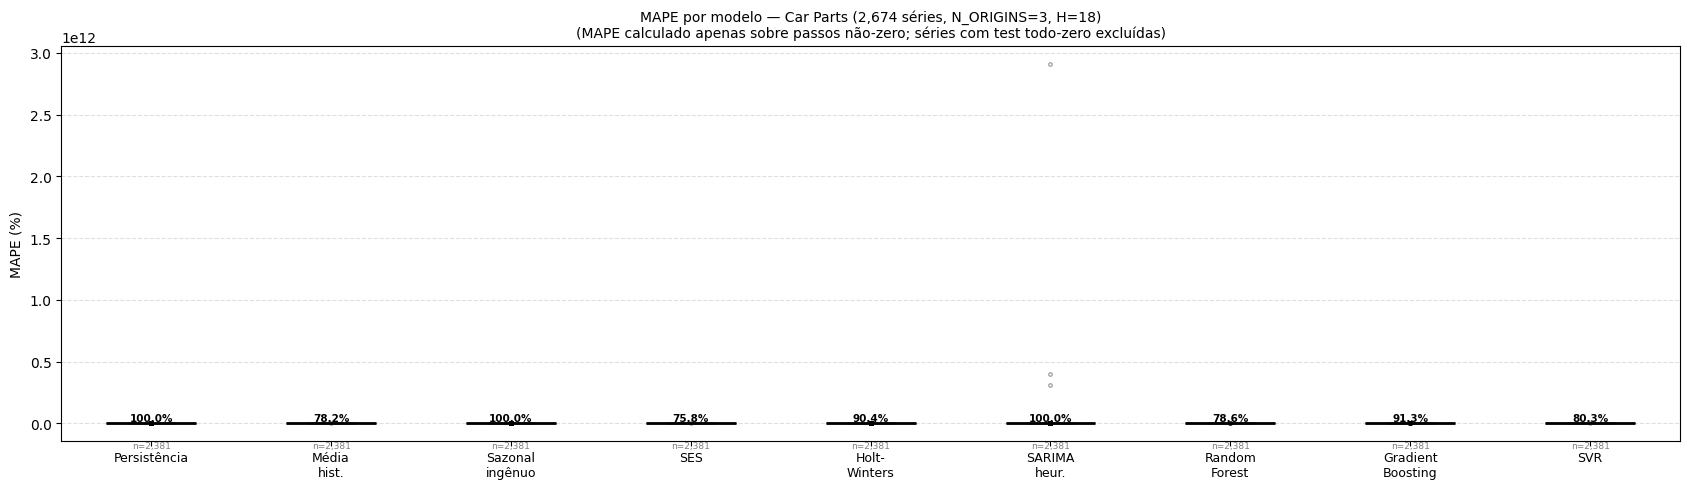

Figura salva: fig_boxplot_cp_mape.png


In [12]:
order_plot = ['persistence', 'mean', 'seasonal_naive', 'ses',
              'holt_winters', 'sarima_heuristic', 'random_forest', 'gbt', 'svr']

name_map_short = {
    'persistence'     : 'Persistência',
    'mean'            : 'Média\nhist.',
    'seasonal_naive'  : 'Sazonal\ningênuo',
    'ses'             : 'SES',
    'holt_winters'    : 'Holt-\nWinters',
    'sarima_heuristic': 'SARIMA\nheur.',
    'random_forest'   : 'Random\nForest',
    'gbt'             : 'Gradient\nBoosting',
    'svr'             : 'SVR',
}

colors_plot = ['#5B8DB8', '#6BAE75', '#E8834E', '#F5C242', '#9B6BB5',
               '#C05050', '#2E8B57', '#FF8C00', '#20B2AA']

order_present = [m for m in order_plot if m in by_series['model'].unique()]

# ── Figura 1: Boxplot de MAPE (apenas séries com MAPE calculável) ─────────────
data_mape = [
    by_series[by_series['model'] == m]['mape'].dropna()
    for m in order_present
]

fig, ax = plt.subplots(figsize=(17, 5))
bp = ax.boxplot(
    data_mape,
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
    flierprops=dict(marker='o', markersize=2.5, alpha=0.35)
)
for patch, color in zip(bp['boxes'], colors_plot[:len(order_present)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_xticks(range(1, len(order_present) + 1))
ax.set_xticklabels([name_map_short[m] for m in order_present], fontsize=9)
ax.set_ylabel('MAPE (%)')
ax.set_title(
    f'MAPE por modelo — Car Parts ({len(valid_ids):,} séries, N_ORIGINS={N_ORIGINS}, H={H})\n'
    f'(MAPE calculado apenas sobre passos não-zero; séries com test todo-zero excluídas)',
    fontsize=10
)
ax.grid(axis='y', linestyle='--', alpha=0.4)

for i, d in enumerate(data_mape):
    if len(d) > 0:
        ax.text(i + 1, d.median(), f'{d.median():.1f}%',
                ha='center', va='bottom', fontsize=7.5, fontweight='bold')
        ax.text(i + 1, ax.get_ylim()[0], f'n={len(d):,}',
                ha='center', va='top', fontsize=6.5, color='gray')

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_boxplot_cp_mape.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva: fig_boxplot_cp_mape.png')

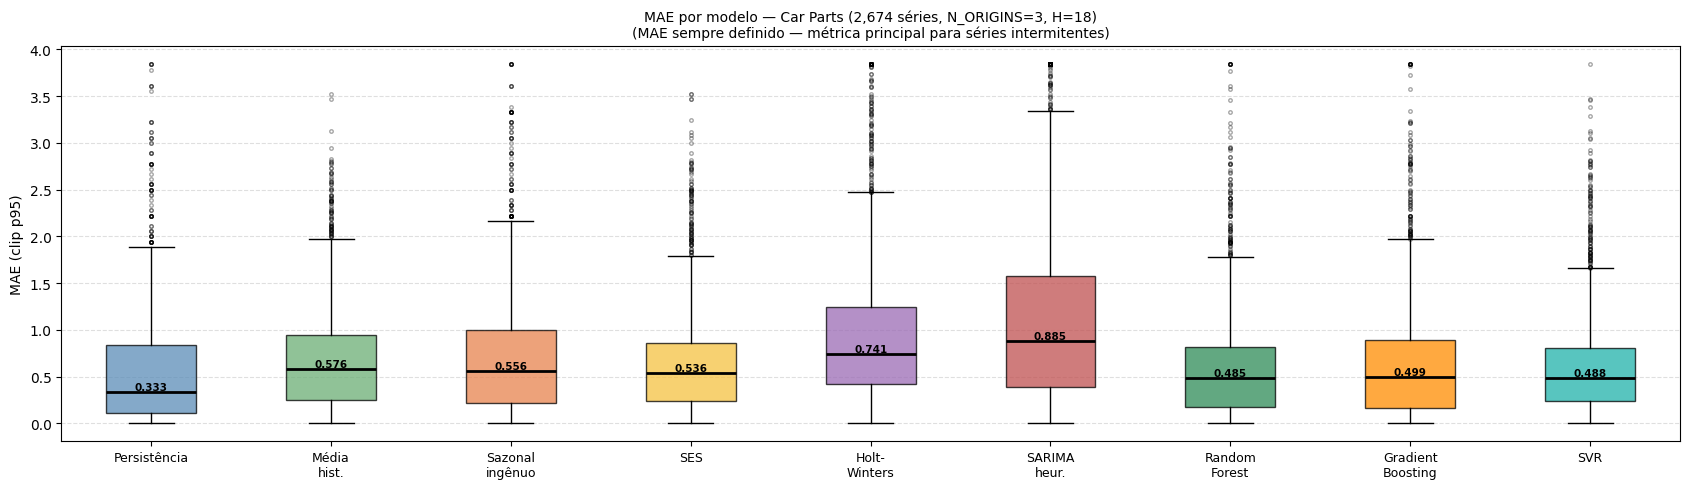

Figura salva: fig_boxplot_cp_mae.png


In [13]:
# ── Figura 2: Boxplot de MAE (métrica sempre definida) ────────────────────────
data_mae = [
    by_series[by_series['model'] == m]['mae'].dropna()
    for m in order_present
]

# Clip para visualização (p95 do maior modelo)
clip_val = max(d.quantile(0.95) for d in data_mae if len(d) > 0)

fig, ax = plt.subplots(figsize=(17, 5))
data_mae_clip = [d.clip(upper=clip_val) for d in data_mae]

bp = ax.boxplot(
    data_mae_clip,
    patch_artist=True,
    medianprops=dict(color='black', linewidth=2),
    flierprops=dict(marker='o', markersize=2.5, alpha=0.35)
)
for patch, color in zip(bp['boxes'], colors_plot[:len(order_present)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)

ax.set_xticks(range(1, len(order_present) + 1))
ax.set_xticklabels([name_map_short[m] for m in order_present], fontsize=9)
ax.set_ylabel('MAE (clip p95)')
ax.set_title(
    f'MAE por modelo — Car Parts ({len(valid_ids):,} séries, N_ORIGINS={N_ORIGINS}, H={H})\n'
    f'(MAE sempre definido — métrica principal para séries intermitentes)',
    fontsize=10
)
ax.grid(axis='y', linestyle='--', alpha=0.4)

for i, (d_orig, d_clip) in enumerate(zip(data_mae, data_mae_clip)):
    if len(d_orig) > 0:
        ax.text(i + 1, d_orig.median(), f'{d_orig.median():.3f}',
                ha='center', va='bottom', fontsize=7.5, fontweight='bold')

plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_boxplot_cp_mae.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva: fig_boxplot_cp_mae.png')

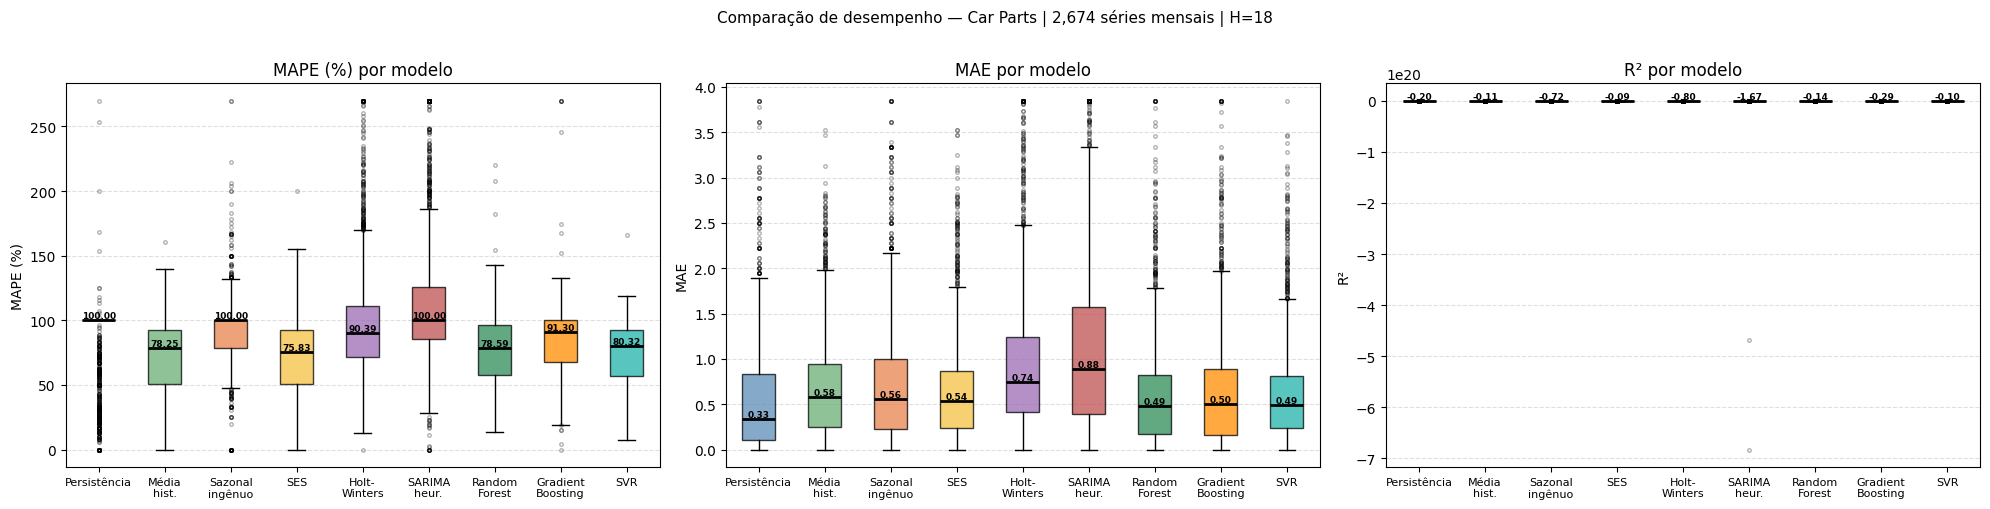

Figura salva: fig_comparacao_3metricas_cp.png


In [14]:
# ── Figura 3: MAPE e MAE side-by-side (3 métricas, formato Figura 8/9) ────────
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, metric, ylabel, use_clip in zip(
    axes,
    ['mape', 'mae', 'r2'],
    ['MAPE (%)', 'MAE', 'R²'],
    [True, True, False]
):
    data_list = [
        by_series[by_series['model'] == m][metric].dropna()
        for m in order_present
    ]

    if use_clip:
        p95 = max((d.quantile(0.95) for d in data_list if len(d) > 0), default=None)
        data_plot = [d.clip(upper=p95) for d in data_list]
    else:
        data_plot = data_list

    bp = ax.boxplot(
        data_plot, patch_artist=True,
        medianprops=dict(color='black', linewidth=2),
        flierprops=dict(marker='o', markersize=2.5, alpha=0.3)
    )
    for patch, color in zip(bp['boxes'], colors_plot[:len(order_present)]):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)

    ax.set_xticks(range(1, len(order_present) + 1))
    ax.set_xticklabels([name_map_short[m] for m in order_present], fontsize=8)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{ylabel} por modelo')
    ax.grid(axis='y', linestyle='--', alpha=0.4)

    for i, d in enumerate(data_list):
        if len(d) > 0:
            ax.text(i + 1, d.median(), f'{d.median():.2f}',
                    ha='center', va='bottom', fontsize=6.5, fontweight='bold')

plt.suptitle(
    f'Comparação de desempenho — Car Parts | {len(valid_ids):,} séries mensais | H={H}',
    fontsize=11, y=1.01
)
plt.tight_layout()
plt.savefig(RESULT_DIR / 'fig_comparacao_3metricas_cp.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figura salva: fig_comparacao_3metricas_cp.png')

## 13. Exemplos visuais — séries com diferentes perfis de zeros

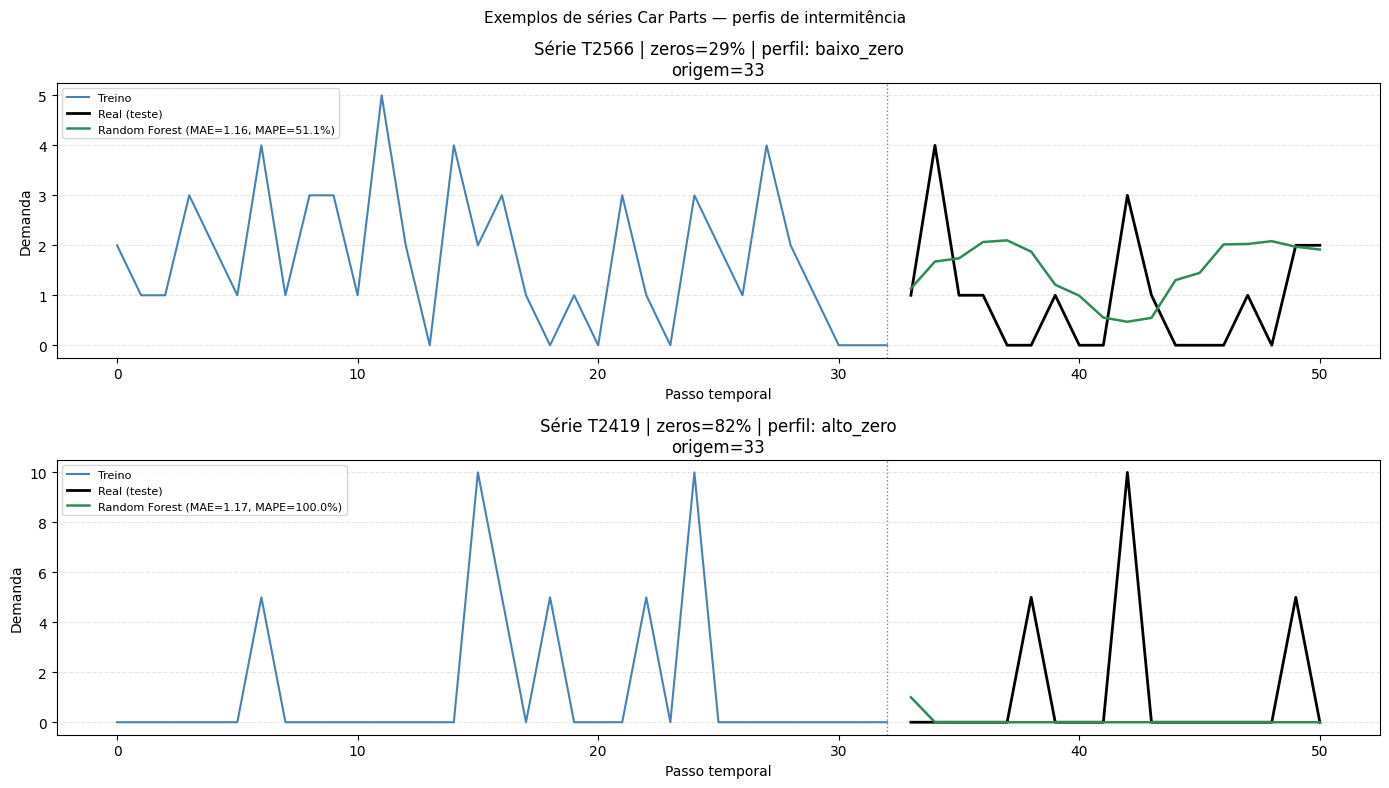

Figura salva: fig_exemplos_cp.png


In [15]:
# Seleciona exemplos com diferentes proporções de zeros
ex_cands = {
    'baixo_zero' : zero_prop_valid[zero_prop_valid < 0.3].index.tolist(),
    'alto_zero'  : zero_prop_valid[(zero_prop_valid >= 0.5) & (zero_prop_valid < 0.9)].index.tolist(),
}

rng = np.random.default_rng(SEED)
examples = {}
for cat, ids in ex_cands.items():
    if ids:
        examples[cat] = rng.choice(ids)

if examples:
    n_ex  = len(examples)
    fig, axes = plt.subplots(n_ex, 1, figsize=(14, 4 * n_ex))
    if n_ex == 1:
        axes = [axes]

    model_preds_config = [
        ('Persistência',   lambda tr: baseline_persistence(tr, H),         '#5B8DB8', '--'),
        ('Sazonal ing.',   lambda tr: baseline_seasonal_naive(tr, H),       '#E8834E', '--'),
        ('Holt-Winters',   lambda tr: holt_winters(tr, H),                  '#9B6BB5', '-'),
        ('Random Forest',  lambda tr: model_random_forest(tr, H),           '#2E8B57', '-'),
    ]

    for ax, (cat, uid) in zip(axes, examples.items()):
        vals = train_df[train_df['unique_id'] == uid]['y'].values.astype(float)
        wins = make_rolling_windows(vals, H, MIN_TRAIN, N_ORIGINS)
        win  = wins[-1]
        zp   = zero_prop_valid[uid]

        x_tr = range(len(win['train']))
        x_te = range(len(win['train']), len(win['train']) + H)

        ax.plot(x_tr, win['train'], color='steelblue', linewidth=1.5, label='Treino')
        ax.plot(x_te, win['test'],  color='black',     linewidth=2,   label='Real (teste)')
        ax.axvline(len(win['train']) - 1, color='gray', linestyle=':', linewidth=1)

        for label, fn, color, ls in model_preds_config:
            try:
                pred = fn(win['train'])
                mae_val  = mean_absolute_error(win['test'], pred)
                mape_val = calc_mape(win['test'], pred)
                mape_str = f'{mape_val:.1f}%' if not np.isnan(mape_val) else 'NaN'
                ax.plot(x_te, pred, color=color, linewidth=1.8, linestyle=ls,
                        label=f'{label} (MAE={mae_val:.2f}, MAPE={mape_str})')
            except Exception:
                pass

        ax.set_title(f'Série {uid} | zeros={zp:.0%} | perfil: {cat}\norigem={win["origin"]}')
        ax.set_xlabel('Passo temporal')
        ax.set_ylabel('Demanda')
        ax.legend(fontsize=8, loc='upper left')
        ax.grid(axis='y', linestyle='--', alpha=0.3)

    plt.suptitle('Exemplos de séries Car Parts — perfis de intermitência', fontsize=11)
    plt.tight_layout()
    plt.savefig(RESULT_DIR / 'fig_exemplos_cp.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Figura salva: fig_exemplos_cp.png')
else:
    print('Nenhum exemplo disponível para plotar.')

## 14. Salvando todos os artefatos e log de execução

In [16]:
# ── Resumo final por modelo ───────────────────────────────────────────────────
final_summary = (
    by_series.groupby('model').agg(
        mape_median    = ('mape', 'median'),
        mae_median     = ('mae',  'median'),
        r2_median      = ('r2',   'median'),
        time_median_s  = ('exec_time_s', 'median'),
        n_series       = ('unique_id', 'nunique'),
    ).round(4)
).sort_values('mae_median')

# Cobertura MAPE
final_summary['mape_cov_pct'] = (
    by_series.groupby('model')['mape'].apply(lambda x: x.notna().mean() * 100).round(1)
)

print('=== Resumo final — Car Parts ===')
print(final_summary.to_string())

# ── Log de execução ───────────────────────────────────────────────────────────
status_counts = {
    name: {
        'ok'   : int((res['status'] == 'OK').sum()),
        'error': int(res['status'].str.startswith('ERROR', na=False).sum()),
        'skip' : int((res['status'] == 'SKIP_SHORT').sum()),
    }
    for name, res in all_results.items()
}

run_log = {
    'timestamp'          : datetime.now().isoformat(),
    'notebook'           : '10_car_parts_pipeline',
    'dataset'            : 'CarParts_Monash',
    'n_series_total'     : int(len(series_lengths)),
    'n_series_valid'     : int(len(valid_ids)),
    'series_length'      : 51,
    'zero_prop_median'   : round(float(zero_prop_valid.median()), 4),
    'seed'               : SEED,
    'horizon_H'          : H,
    'min_train'          : MIN_TRAIN,
    'n_origins'          : N_ORIGINS,
    'models'             : [name for name, _ in models_to_run],
    'sarima_auto_excluido': True,
    'sarima_auto_motivo' : 'Restrição operacional: custo computacional excessivo (2674 séries × 3 origens)',
    'status_counts'      : status_counts,
    'results_summary'    : final_summary.round(4).to_dict(),
}

with open(RESULT_DIR / 'run_log_cp.json', 'w', encoding='utf-8') as f:
    json.dump(run_log, f, indent=2, default=str)

# ── Lista de artefatos salvos ─────────────────────────────────────────────────
print('\nArtefatos salvos em results/car_parts/:')
for f in sorted(RESULT_DIR.glob('*')):
    sz = f.stat().st_size
    sz_str = f'{sz/1024:.1f} KB' if sz < 1_048_576 else f'{sz/1_048_576:.1f} MB'
    print(f'  {f.name:<55} {sz_str}')

=== Resumo final — Car Parts ===
                  mape_median  mae_median  r2_median  time_median_s  n_series  mape_cov_pct
model                                                                                      
persistence          100.0000      0.3333    -0.2000         0.0004      2674          89.0
random_forest         78.5880      0.4851    -0.1388         0.0590      2674          89.0
svr                   80.3236      0.4877    -0.0976         0.0091      2674          89.0
gbt                   91.3015      0.4994    -0.2857         0.0370      2674          89.0
ses                   75.8281      0.5357    -0.0949         0.0032      2674          89.0
seasonal_naive       100.0000      0.5556    -0.7215         0.0004      2674          89.0
mean                  78.2468      0.5758    -0.1111         0.0004      2674          89.0
holt_winters          90.3865      0.7408    -0.8001         0.0532      2674          89.0
sarima_heuristic     100.0000      0.8846    -1

## 15. Resumo e interpretação

---

### Contexto metodológico

Este notebook replica o pipeline dos notebooks 02–07 no **Car Parts Dataset**, um conjunto  
de demanda intermitente com características opostas ao M4 mensal:

| Característica | M4 Monthly (NB 02–07) | Car Parts (NB 10) |
|---|---|---|
| Natureza | Séries econômicas/demográficas | Demanda intermitente |
| Zeros | Raros | Dominantes (>50% em maioria das séries) |
| Padrão sazonal | Forte e regular | Fraco ou ausente |
| Comprimento | Variável (médio ~200 obs) | Fixo (51 obs) |
| MAPE calculável | Sempre | Parcial (exclui janelas all-zero) |

### Implicações para a dissertação

- **Validade externa**: Se a ordenação relativa dos modelos for similar ao M4 → evidência de  
  generalização. Se diferente → o tipo de série modera o desempenho relativo.
- **Métrica primária**: Com alta proporção de zeros, o **MAE é mais confiável que o MAPE**  
  para comparação entre modelos neste dataset.
- **Modelos à base de média** (SES, média histórica): tendem a ser mais robustos em séries  
  intermitentes, pois minimizam o erro quadrático médio que penaliza desvios de uma série quase nula.
- **Modelos sazonais** (HW, SARIMA, sazonal ingênuo): podem ser prejudicados pela falta de  
  padrão sazonal claro nas séries de demanda de peças.

### Restrições operacionais documentadas

| Modelo | Restrição |
|---|---|
| SARIMA automático | Excluído: custo computacional excessivo (mesmo critério do NB08) |
| MAPE | Indefinido para janelas com test todo-zero → MAE como fallback |
| Holt-Winters mul. | Indisponível para séries com zeros → apenas aditivo |
| SVR / SARIMA | Fallback para média/sazonal ingênuo em séries constantes |

---

### Arquivos gerados em `results/car_parts/`

| Arquivo | Conteúdo |
|---|---|
| `results_cp_by_window.csv` | Métricas por janela rolling (todos os modelos) |
| `results_cp_by_series.csv` | Mediana por série × modelo |
| `results_cp_{model}_by_window.csv` | Cache por modelo (9 arquivos) |
| `tabela_comparativa_cp.csv` | Tabela 3 equivalente — mediana entre séries |
| `tabela_mae_por_zeros_cp.csv` | MAE por faixa de proporção de zeros |
| `run_log_cp.json` | Log completo de execução |
| `fig_eda_car_parts.png` | EDA exploratória |
| `fig_boxplot_cp_mape.png` | Figura 8 equivalente — MAPE |
| `fig_boxplot_cp_mae.png` | Figura 9 equivalente — MAE |
| `fig_comparacao_3metricas_cp.png` | MAPE + MAE + R² lado a lado |
| `fig_exemplos_cp.png` | Exemplos visuais de séries |
